# Projet Machine Learning — Adult Dataset
**Noms :** ..........  
**Date :** 29/09/2026  
**Dataset :** Adult Census Income (UCI Machine Learning Repository)


## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

---
## 2. Compréhension Métier

Le dataset **Adult** (aussi appelé *Census Income*) a été extrait de la base de données du recensement américain de **1994** par Barry Becker.  

**Problème métier :** Prédire si le revenu annuel d'une personne est **supérieur ou inférieur à 50 000$** à partir de ses caractéristiques socio-démographiques (âge, niveau d'éducation, profession, etc.).

Ce type de problème est utile dans plusieurs domaines :
- **Banque / Assurance** : évaluer la solvabilité d'un client
- **Marketing** : cibler les campagnes selon le niveau de revenu
- **Politiques sociales** : identifier les populations à faibles revenus

C'est un problème de **classification binaire** :
- Classe 1 : revenu **> 50K**
- Classe 0 : revenu **<= 50K**

---
## 3. Compréhension des Données

### 3.1 Description des variables

Le dataset contient **15 variables** (14 features + 1 variable cible) :

| Variable | Type | Description |
|----------|------|-------------|
| age | Continue | Âge de la personne |
| workclass | Catégorielle | Secteur d'activité (privé, public, indépendant...) |
| fnlwgt | Continue | Poids final de recensement (pondération statistique) |
| education | Catégorielle | Niveau d'éducation (libellé) |
| education-num | Continue | Niveau d'éducation (numérique) |
| marital-status | Catégorielle | Statut matrimonial |
| occupation | Catégorielle | Profession |
| relationship | Catégorielle | Lien familial |
| race | Catégorielle | Origine ethnique |
| sex | Catégorielle | Sexe |
| capital-gain | Continue | Gains en capital |
| capital-loss | Continue | Pertes en capital |
| hours-per-week | Continue | Heures travaillées par semaine |
| native-country | Catégorielle | Pays d'origine |
| income | **Cible** | >50K ou <=50K |

### 3.2 Chargement des données

In [2]:
# Noms des colonnes
colonnes = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
]

# Chargement du fichier principal (les '?' sont des valeurs manquantes)
df = pd.read_csv('adult.data', names=colonnes, sep=',\s*', engine='python', na_values='?')

print("Taille du dataset :", df.shape)
print("Nombre de lignes  :", df.shape[0])
print("Nombre de colonnes:", df.shape[1])

Taille du dataset : (32561, 15)
Nombre de lignes  : 32561
Nombre de colonnes: 15


In [3]:
# Afficher les 5 premières lignes
df.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
# Informations générales sur le dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [5]:
# Statistiques descriptives des variables numériques
df.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [6]:
# Statistiques des variables catégorielles
df.describe(include='object')

,workclass,education,marital_status,occupation,relationship,race,sex,native_country,income
count,30725,32561,32561,30718,32561,32561,32561,31978,32561
unique,8,16,7,14,6,5,2,41,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,22696,10501,14976,4140,13193,27816,21790,29170,24720


### 3.3 Distribution de la variable cible

In [7]:
# Comptage des classes
print("Distribution de la variable cible (income) :")
print(df['income'].value_counts())
print()
print("En pourcentage :")
print(df['income'].value_counts(normalize=True).round(3) * 100)

Distribution de la variable cible (income) :
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

En pourcentage :
income
<=50K    75.9
>50K     24.1
Name: proportion, dtype: float64


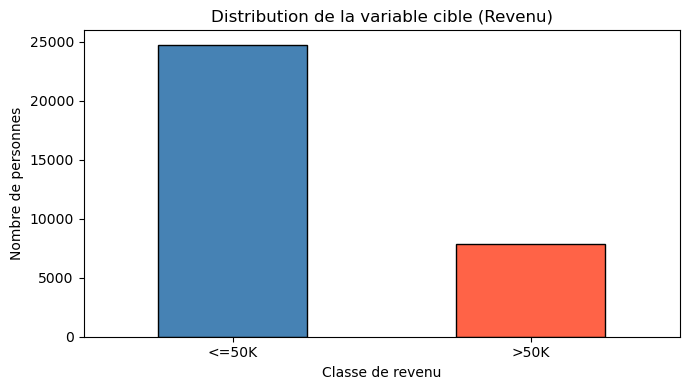

Observation : Le dataset est desequilibre. 76% des personnes gagnent <= 50K.


In [8]:
# Visualisation de la variable cible
plt.figure(figsize=(7, 4))
df['income'].value_counts().plot(kind='bar', color=['steelblue', 'tomato'], edgecolor='black')
plt.title("Distribution de la variable cible (Revenu)")
plt.xlabel("Classe de revenu")
plt.ylabel("Nombre de personnes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('cible.png', dpi=120)
plt.show()

print("Observation : Le dataset est desequilibre. 76% des personnes gagnent <= 50K.")

### 3.4 Exploration des variables numériques

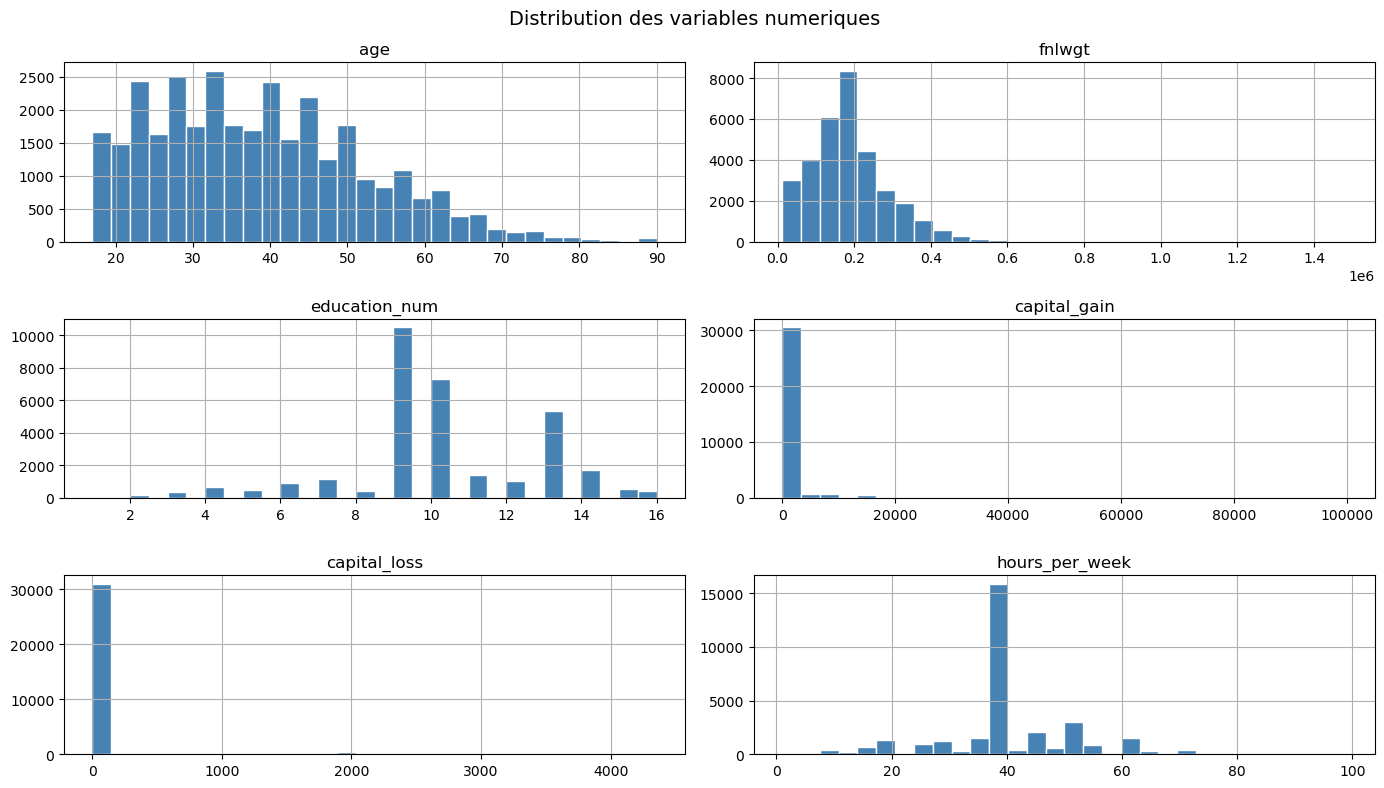

In [9]:
# Variables numériques
variables_num = ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

# Histogrammes
df[variables_num].hist(bins=30, figsize=(14, 8), color='steelblue', edgecolor='white')
plt.suptitle("Distribution des variables numeriques", fontsize=14)
plt.tight_layout()
plt.savefig('histogrammes.png', dpi=120)
plt.show()

### 3.5 Exploration des variables catégorielles

In [10]:
# Afficher le nombre de modalités par variable catégorielle
variables_cat = ['workclass', 'education', 'marital_status', 'occupation', 
                 'relationship', 'race', 'sex', 'native_country']

print("Nombre de modalites par variable categorielle :")
for col in variables_cat:
    print(f"  {col} : {df[col].nunique()} modalites")
    print(f"     -> {df[col].value_counts().head(3).to_dict()}")
    print()

Nombre de modalites par variable categorielle :
  workclass : 8 modalites
     -> {'Private': 22696, 'Self-emp-not-inc': 2541, 'Local-gov': 2093}

  education : 16 modalites
     -> {'HS-grad': 10501, 'Some-college': 7291, 'Bachelors': 5355}

  marital_status : 7 modalites
     -> {'Married-civ-spouse': 14976, 'Never-married': 10683, 'Divorced': 4443}

  occupation : 14 modalites
     -> {'Prof-specialty': 4140, 'Craft-repair': 4099, 'Exec-managerial': 4066}

  relationship : 6 modalites
     -> {'Husband': 13193, 'Not-in-family': 8305, 'Own-child': 5068}

  race : 5 modalites
     -> {'White': 27816, 'Black': 3124, 'Asian-Pac-Islander': 1039}

  sex : 2 modalites
     -> {'Male': 21790, 'Female': 10771}

  native_country : 41 modalites
     -> {'United-States': 29170, 'Mexico': 643, 'Philippines': 198}



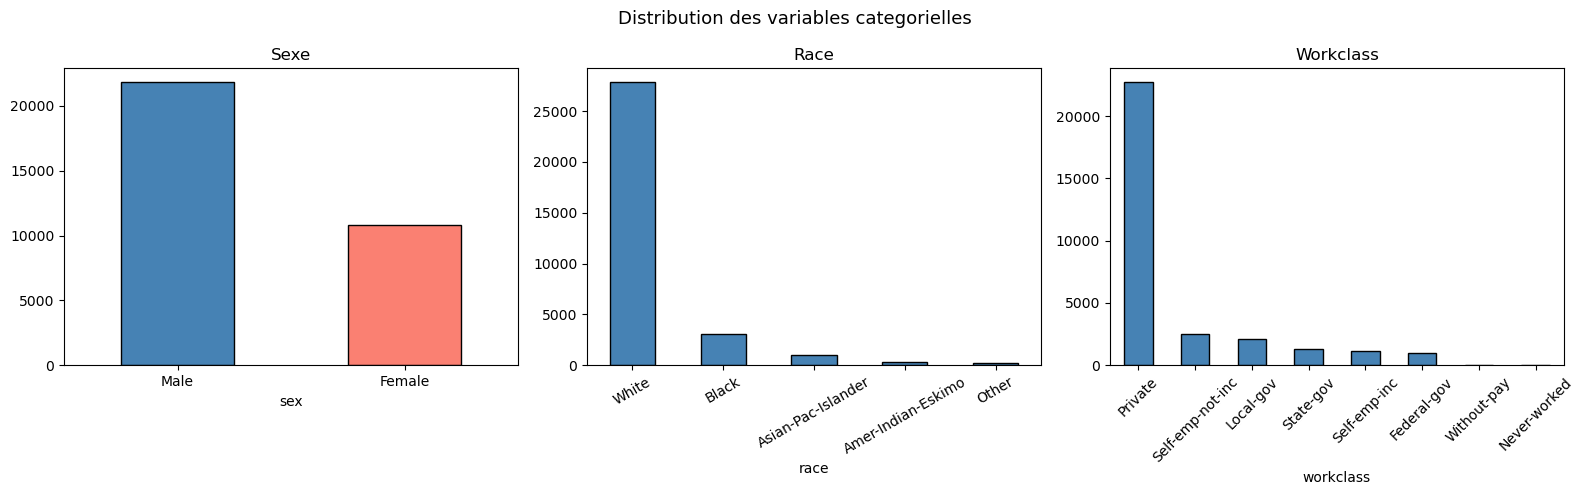

In [11]:
# Graphique : répartition de quelques variables catégorielles
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

df['sex'].value_counts().plot(kind='bar', ax=axes[0], color=['steelblue', 'salmon'], edgecolor='black')
axes[0].set_title("Sexe")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

df['race'].value_counts().plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='black')
axes[1].set_title("Race")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30)

df['workclass'].value_counts().plot(kind='bar', ax=axes[2], color='steelblue', edgecolor='black')
axes[2].set_title("Workclass")
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=45)

plt.suptitle("Distribution des variables categorielles", fontsize=13)
plt.tight_layout()
plt.savefig('categories.png', dpi=120)
plt.show()

---
## 4. Data Cleaning (Nettoyage des données)

Nous allons traiter :
1. Les **valeurs manquantes** (notées `?` dans le fichier original, converties en `NaN`)
2. Les **valeurs aberrantes** (outliers)
3. Les **données redondantes**

### 4.1 Valeurs manquantes

In [12]:
# Compter les valeurs manquantes par colonne
valeurs_manquantes = df.isnull().sum()
pourcentage = (df.isnull().sum() / len(df)) * 100

tableau_manquants = pd.DataFrame({
    'Valeurs manquantes': valeurs_manquantes,
    'Pourcentage (%)': pourcentage.round(2)
})

# Afficher seulement les colonnes qui ont des manquants
tableau_manquants = tableau_manquants[tableau_manquants['Valeurs manquantes'] > 0]
print("Colonnes avec valeurs manquantes :")
print(tableau_manquants)
print()
print("Total de valeurs manquantes dans tout le dataset :", df.isnull().sum().sum())

Colonnes avec valeurs manquantes :
                Valeurs manquantes  Pourcentage (%)
workclass                     1836             5.64
occupation                    1843             5.66
native_country                 583             1.79

Total de valeurs manquantes dans tout le dataset : 4262


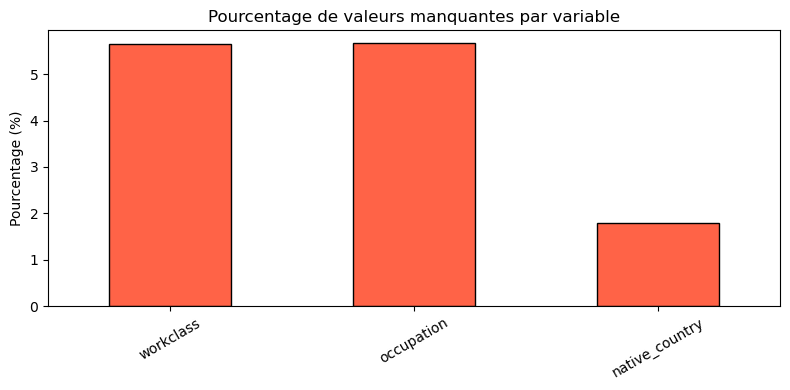

In [13]:
# Visualisation des valeurs manquantes
plt.figure(figsize=(8, 4))
tableau_manquants['Pourcentage (%)'].plot(kind='bar', color='tomato', edgecolor='black')
plt.title("Pourcentage de valeurs manquantes par variable")
plt.ylabel("Pourcentage (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('valeurs_manquantes.png', dpi=120)
plt.show()

In [14]:
# Traitement des valeurs manquantes
# On fait une copie pour ne pas modifier l'original
df_clean = df.copy()

# Stratégie : remplacer par le mode (valeur la plus fréquente) car variables catégorielles
colonnes_manquantes = ['workclass', 'occupation', 'native_country']

for col in colonnes_manquantes:
    mode = df_clean[col].mode()[0]  # prendre la valeur la plus fréquente
    nb_avant = df_clean[col].isnull().sum()
    df_clean[col].fillna(mode, inplace=True)
    print(f"{col} : {nb_avant} valeurs manquantes remplacees par '{mode}'")

print()
print("Valeurs manquantes restantes :", df_clean.isnull().sum().sum())
print("-> Toutes les valeurs manquantes ont ete traitees !")

workclass : 1836 valeurs manquantes remplacees par 'Private'
occupation : 1843 valeurs manquantes remplacees par 'Prof-specialty'
native_country : 583 valeurs manquantes remplacees par 'United-States'

Valeurs manquantes restantes : 0
-> Toutes les valeurs manquantes ont ete traitees !


**Justification :** Nous avons choisi d'imputer par le **mode** car les 3 variables concernées (`workclass`, `occupation`, `native_country`) sont catégorielles. Le mode représente la modalité la plus courante dans la population, ce qui est une hypothèse raisonnable pour des données de recensement.

### 4.2 Valeurs aberrantes (Outliers)

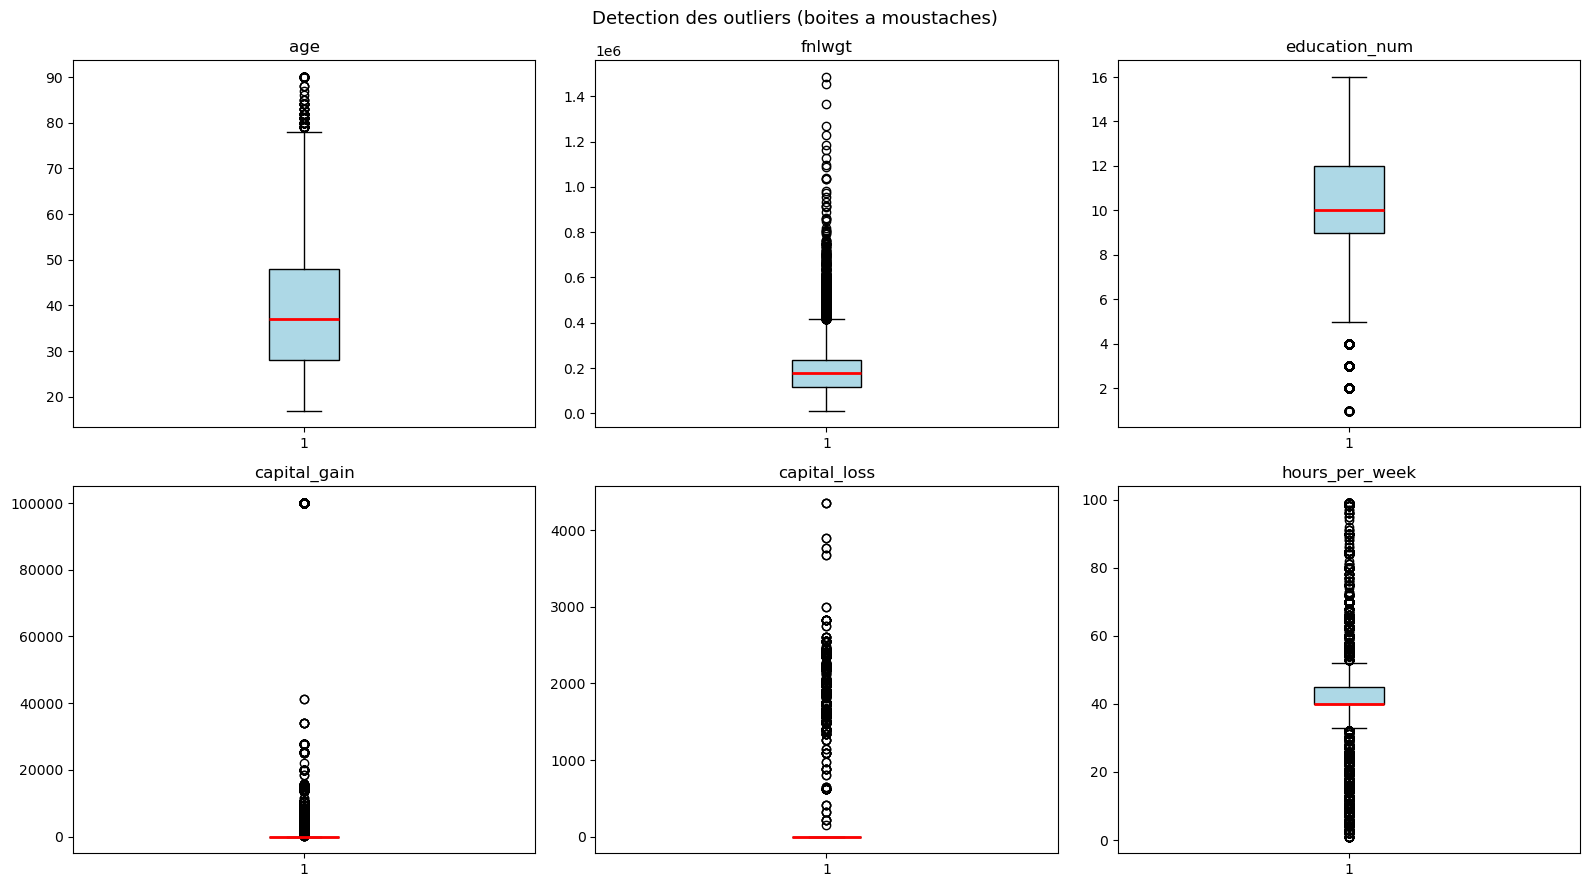

In [15]:
# Détection avec les boites à moustaches (boxplot)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(variables_num):
    axes[i].boxplot(df_clean[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor='lightblue'),
                    medianprops=dict(color='red', linewidth=2))
    axes[i].set_title(col)

plt.suptitle("Detection des outliers (boites a moustaches)", fontsize=13)
plt.tight_layout()
plt.savefig('boxplots.png', dpi=120)
plt.show()

In [16]:
# Calcul des outliers avec la méthode IQR (Inter-Quartile Range)
print("Analyse des outliers par variable (methode IQR) :")
print("-" * 55)

for col in variables_num:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR
    
    # Compter les outliers
    nb_outliers = ((df_clean[col] < borne_inf) | (df_clean[col] > borne_sup)).sum()
    pct = round(nb_outliers / len(df_clean) * 100, 2)
    
    print(f"{col}")
    print(f"   Q1={Q1:.1f}, Q3={Q3:.1f}, IQR={IQR:.1f}")
    print(f"   Bornes : [{borne_inf:.1f} ; {borne_sup:.1f}]")
    print(f"   Nombre d'outliers : {nb_outliers} ({pct}%)")
    print()

Analyse des outliers par variable (methode IQR) :
-------------------------------------------------------
age
   Q1=28.0, Q3=48.0, IQR=20.0
   Bornes : [-2.0 ; 78.0]
   Nombre d'outliers : 143 (0.44%)

fnlwgt
   Q1=117827.0, Q3=237051.0, IQR=119224.0
   Bornes : [-61009.0 ; 415887.0]
   Nombre d'outliers : 992 (3.05%)

education_num
   Q1=9.0, Q3=12.0, IQR=3.0
   Bornes : [4.5 ; 16.5]
   Nombre d'outliers : 1198 (3.68%)

capital_gain
   Q1=0.0, Q3=0.0, IQR=0.0
   Bornes : [0.0 ; 0.0]
   Nombre d'outliers : 2712 (8.33%)

capital_loss
   Q1=0.0, Q3=0.0, IQR=0.0
   Bornes : [0.0 ; 0.0]
   Nombre d'outliers : 1519 (4.67%)

hours_per_week
   Q1=40.0, Q3=45.0, IQR=5.0
   Bornes : [32.5 ; 52.5]
   Nombre d'outliers : 9008 (27.66%)



In [17]:
# Analyse détaillée de hours_per_week
print("Analyse de hours_per_week :")
print("  Minimum :", df_clean['hours_per_week'].min())
print("  Maximum :", df_clean['hours_per_week'].max())
print("  Moyenne :", round(df_clean['hours_per_week'].mean(), 2))
print()

# On considère que plus de 80h/semaine est suspect
suspects = df_clean[df_clean['hours_per_week'] > 80]
print(f"Personnes travaillant plus de 80h/semaine : {len(suspects)} ({round(len(suspects)/len(df_clean)*100, 2)}%)")

Analyse de hours_per_week :
  Minimum : 1
  Maximum : 99
  Moyenne : 40.44

Personnes travaillant plus de 80h/semaine : 208 (0.64%)


In [18]:
# Traitement des outliers
# Pour hours_per_week : on applique le capping (plafonner à 80h max)
# Justification : une semaine compte 168h max, mais 80h est déjà extrême

nb_avant = (df_clean['hours_per_week'] > 80).sum()
df_clean['hours_per_week'] = df_clean['hours_per_week'].clip(upper=80)

print(f"hours_per_week : {nb_avant} valeurs > 80h plafonnees a 80h (capping)")
print(f"Nouveau maximum : {df_clean['hours_per_week'].max()}h")
print()

# Pour capital_gain et capital_loss : on les garde
# Justification : les valeurs élevées sont réelles (vrais investissements),
# pas des erreurs de saisie
print("capital_gain et capital_loss : outliers conserves")
print("Justification : valeurs financieres reelles, pas des erreurs de mesure")
print()

# Pour age : pas de traitement
# age max = 90, plausible pour un recensement
print("age : pas de traitement (valeurs extremes plausibles, age max =", df_clean['age'].max(), ")")

hours_per_week : 208 valeurs > 80h plafonnees a 80h (capping)
Nouveau maximum : 80h

capital_gain et capital_loss : outliers conserves
Justification : valeurs financieres reelles, pas des erreurs de mesure

age : pas de traitement (valeurs extremes plausibles, age max = 90 )


### 4.3 Données redondantes

In [19]:
# 1. Vérification des doublons
nb_doublons = df_clean.duplicated().sum()
print(f"Nombre de lignes dupliquees : {nb_doublons}")

if nb_doublons > 0:
    print("Suppression des doublons...")
    df_clean = df_clean.drop_duplicates()
    print(f"Doublons supprimes. Nouvelle taille : {df_clean.shape}")
else:
    print("Aucun doublon exact detecte.")

Nombre de lignes dupliquees : 24
Suppression des doublons...
Doublons supprimes. Nouvelle taille : (32537, 15)


In [20]:
# 2. Vérification de la redondance entre 'education' et 'education_num'
print("Correspondance entre education (texte) et education_num (nombre) :")
print()
correspondance = df_clean.groupby('education')['education_num'].unique().reset_index()
correspondance.columns = ['education', 'education_num']
print(correspondance.sort_values('education_num').to_string(index=False))

Correspondance entre education (texte) et education_num (nombre) :

   education education_num
   Preschool           [1]
     1st-4th           [2]
     5th-6th           [3]
     7th-8th           [4]
         9th           [5]
        10th           [6]
        11th           [7]
        12th           [8]
     HS-grad           [9]
Some-college          [10]
   Assoc-voc          [11]
  Assoc-acdm          [12]
   Bachelors          [13]
     Masters          [14]
 Prof-school          [15]
   Doctorate          [16]


In [21]:
# Vérification : est-ce que chaque niveau éducation correspond à UN seul numéro ?
est_redondant = all(len(v) == 1 for v in df_clean.groupby('education')['education_num'].unique())

print(f"Est-ce que 'education' et 'education_num' donnent la meme information ? {est_redondant}")
print()
if est_redondant:
    print("Conclusion : 'education' (texte) et 'education_num' (nombre) sont REDONDANTES.")
    print("=> On va supprimer 'education' et garder 'education_num' (plus utile pour le ML).")
    df_clean = df_clean.drop(columns=['education'])
    print("Variable 'education' supprimee.")

Est-ce que 'education' et 'education_num' donnent la meme information ? True

Conclusion : 'education' (texte) et 'education_num' (nombre) sont REDONDANTES.
=> On va supprimer 'education' et garder 'education_num' (plus utile pour le ML).
Variable 'education' supprimee.


In [22]:
# 3. La variable fnlwgt (poids de recensement)
print("Variable 'fnlwgt' :")
print("  Description : poids statistique attribue par le bureau du recensement")
print("  Cette variable represente la ponderation de la personne dans la population.")
print("  Elle n'a PAS de sens direct pour predire le revenu individuel.")
print()
print("Correlation avec le revenu :")

# Encode income pour calculer la corrélation
income_num = (df_clean['income'] == '>50K').astype(int)
corr = df_clean['fnlwgt'].corr(income_num)
print(f"  Correlation de fnlwgt avec income : {corr:.4f}")
print()
print("Conclusion : fnlwgt est quasi non-correllee avec le revenu.")
print("=> On la supprime car elle n'apporte pas d'information predictive.")

df_clean = df_clean.drop(columns=['fnlwgt'])
print("Variable 'fnlwgt' supprimee.")

Variable 'fnlwgt' :
  Description : poids statistique attribue par le bureau du recensement
  Cette variable represente la ponderation de la personne dans la population.
  Elle n'a PAS de sens direct pour predire le revenu individuel.

Correlation avec le revenu :
  Correlation de fnlwgt avec income : -0.0095

Conclusion : fnlwgt est quasi non-correllee avec le revenu.
=> On la supprime car elle n'apporte pas d'information predictive.
Variable 'fnlwgt' supprimee.


---
## 5. Résumé du nettoyage

In [23]:
print("=" * 55)
print("RESUME DU DATA CLEANING")
print("=" * 55)
print()
print(f"Taille initiale du dataset : {df.shape[0]} lignes x {df.shape[1]} colonnes")
print(f"Taille apres nettoyage     : {df_clean.shape[0]} lignes x {df_clean.shape[1]} colonnes")
print()
print("1. VALEURS MANQUANTES :")
print("   - workclass      : imputation par le mode")
print("   - occupation     : imputation par le mode")
print("   - native_country : imputation par le mode")
print()
print("2. VALEURS ABERRANTES (OUTLIERS) :")
print("   - hours_per_week : capping a 80h/semaine")
print("   - capital_gain / capital_loss : conserves (valeurs reelles)")
print("   - age : conserve (valeurs plausibles)")
print()
print("3. DONNEES REDONDANTES :")
print("   - education : supprimee (identique a education_num)")
print("   - fnlwgt    : supprimee (non predictive)")
print()
print("Dataset pret pour les prochaines etapes !")
print("=" * 55)

RESUME DU DATA CLEANING

Taille initiale du dataset : 32561 lignes x 15 colonnes
Taille apres nettoyage     : 32537 lignes x 13 colonnes

1. VALEURS MANQUANTES :
   - workclass      : imputation par le mode
   - occupation     : imputation par le mode
   - native_country : imputation par le mode

2. VALEURS ABERRANTES (OUTLIERS) :
   - hours_per_week : capping a 80h/semaine
   - capital_gain / capital_loss : conserves (valeurs reelles)
   - age : conserve (valeurs plausibles)

3. DONNEES REDONDANTES :
   - education : supprimee (identique a education_num)
   - fnlwgt    : supprimee (non predictive)

Dataset pret pour les prochaines etapes !


In [24]:
# Aperçu du dataset nettoyé
print("Colonnes restantes dans le dataset nettoye :")
print(df_clean.columns.tolist())
print()
df_clean.head()

Colonnes restantes dans le dataset nettoye :
['age', 'workclass', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']



,age,workclass,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
